In [22]:
# Cell 2
# Import Python libraries

import requests
import json
import cv2
import matplotlib.pyplot as plt

from google.colab import files

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
# Cell 3
# Roboflow API configuration

import os
from dotenv import load_dotenv

# Load .env file
load_dotenv()

# Get API key securely
API_KEY = os.getenv("ROBOFLOW_API_KEY")

if not API_KEY:
    raise ValueError(
        "ROBOFLOW_API_KEY not found. "
        "Make sure .env exists in the project folder."
    )

WORKSPACE_NAME = "aakash-kumar-m8v4k"

WORKFLOW_ID = "general-segmentation-api-5"

API_URL = (
    f"https://serverless.roboflow.com/"
    f"{WORKSPACE_NAME}/workflows/{WORKFLOW_ID}"
)

print("Roboflow API configured")
print("Workflow:", WORKFLOW_ID)
print("API key loaded: Yes")

Roboflow API configured
Workflow: general-segmentation-api-5


In [26]:
# Cell 4
# Upload a vehicle image

uploaded = files.upload()

IMAGE_PATH = list(uploaded.keys())[0]

print("Selected image:", IMAGE_PATH)

Saving images (1).jpg to images (1).jpg
Selected image: images (1).jpg


Image loaded successfully
Image size: (554, 554, 3)


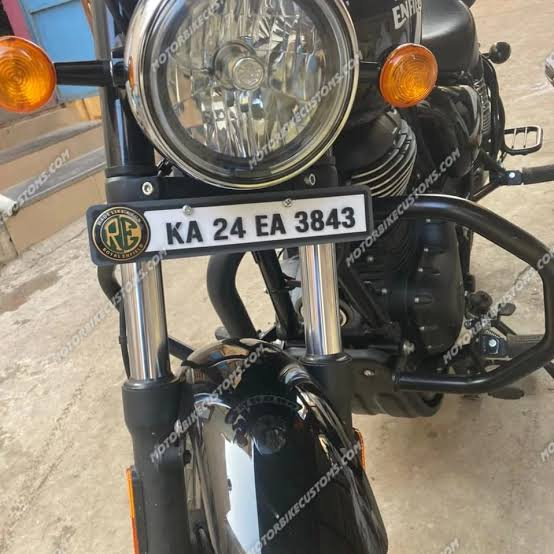

In [28]:
# Cell 5
# Display the uploaded image

from google.colab.patches import cv2_imshow

image = cv2.imread(IMAGE_PATH)

if image is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully")
print("Image size:", image.shape)

cv2_imshow(image)

In [30]:
# Cell 6
# Convert the image into Base64 so we can send it to the API

import base64

with open(IMAGE_PATH, "rb") as image_file:
    image_bytes = image_file.read()

image_base64 = base64.b64encode(image_bytes).decode("utf-8")

print("Image converted successfully")

Image converted successfully


In [35]:
# Cell 7
# Send image + vehicle classes to Roboflow

headers = {
    "Content-Type": "application/json"
}

payload = {
    "api_key": API_KEY,

    "inputs": {
        "image": {
            "type": "base64",
            "value": image_base64
        },

        # Tell the workflow which vehicle classes we want
        "classes": "car, truck, bus, bicycle, motorcycle"
    }
}

response = requests.post(
    API_URL,
    headers=headers,
    json=payload
)

print("Status code:", response.status_code)

Status code: 200


In [36]:
# Cell 8
# Check the response returned by Roboflow

print("Status code:", response.status_code)

if response.ok:

    result = response.json()

    print("SUCCESS!")
    print(json.dumps(result, indent=2)[:8000])

else:

    print("Roboflow returned an error:")
    print(response.text)

Status code: 200
SUCCESS!
{
  "outputs": [
    {
      "annotated_image": {
        "type": "base64",
        "value": "/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAIBAQEBAQIBAQECAgICAgQDAgICAgUEBAMEBgUGBgYFBgYGBwkIBgcJBwYGCAsICQoKCgoKBggLDAsKDAkKCgr/2wBDAQICAgICAgUDAwUKBwYHCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgoKCgr/wAARCAIqAioDASIAAhEBAxEB/8QAHwAAAQUBAQEBAQEAAAAAAAAAAAECAwQFBgcICQoL/8QAtRAAAgEDAwIEAwUFBAQAAAF9AQIDAAQRBRIhMUEGE1FhByJxFDKBkaEII0KxwRVS0fAkM2JyggkKFhcYGRolJicoKSo0NTY3ODk6Q0RFRkdISUpTVFVWV1hZWmNkZWZnaGlqc3R1dnd4eXqDhIWGh4iJipKTlJWWl5iZmqKjpKWmp6ipqrKztLW2t7i5usLDxMXGx8jJytLT1NXW19jZ2uHi4+Tl5ufo6erx8vP09fb3+Pn6/8QAHwEAAwEBAQEBAQEBAQAAAAAAAAECAwQFBgcICQoL/8QAtREAAgECBAQDBAcFBAQAAQJ3AAECAxEEBSExBhJBUQdhcRMiMoEIFEKRobHBCSMzUvAVYnLRChYkNOEl8RcYGRomJygpKjU2Nzg5OkNERUZHSElKU1RVVldYWVpjZGVmZ2hpanN0dXZ3eHl6goOEhYaHiImKkpOUlZaXmJmaoqOkpaanqKmqsrO0tba3uLm6wsPExcbHyMnK0tPU1dbX2Nna4uPk5ebn6Onq8vP09fb3+Pn6/9oADAMBAAIRAxEAPwDxf9jr9sH46fFr4ZyNefFXxZJc6dfmGW4vPEd1LI8ZG9CWZySc

In [37]:
# Cell 9
# Find the vehicle predictions returned by Roboflow

def find_predictions(data):

    # If we find a dictionary containing "predictions"
    if isinstance(data, dict):

        if "predictions" in data:
            predictions = data["predictions"]

            if isinstance(predictions, list):
                return predictions

        # Search inside nested dictionaries
        for value in data.values():
            result = find_predictions(value)

            if result is not None:
                return result

    # Search inside lists
    elif isinstance(data, list):

        for item in data:
            result = find_predictions(item)

            if result is not None:
                return result

    return None


predictions = find_predictions(result)

if predictions is None:
    print("No predictions found.")
    print("Let's inspect the response:")
    print(json.dumps(result, indent=2)[:10000])

else:
    print("Predictions found:", len(predictions))

    for prediction in predictions:
        print(prediction)

Predictions found: 1
{'width': 554.0, 'height': 554.0, 'x': 277.0, 'y': 277.0, 'confidence': 0.87109375, 'class_id': 4, 'class': ' motorcycle', 'detection_id': '408dded4-400c-4331-a959-2521c417d9ea', 'parent_id': 'image', 'rle_mask': {'size': [554, 554], 'counts': 'W1i0d0Mc>3\\AOb>2]AOc>1]A0b>0TAXOOi0m>OTAXOOi0m>OUAWOMl0l>NVAXOMj0m>NVAXOLk0n>Mo@WO4S1m>Fo@XO3R1n>JQA8n>HRA8n>R10010O01O000000010O001N10001O1O00001N101N2O001N1O2O1O1N2N2N102M2N3M3M2M3M3M2N3M3L3O1N1O21O001O0000000000001O0000000000000000000O10000000000000000000000\\CEX8<fGMS83lG:h7FWHd0e5oNPH=Z2k0^5ROPH3b2m0\\5]OeGGm2n0]5@aGBR3P1[5D\\G]OY3P1Z50oFQOg3P1Y5l0fJAm4?SKEi4;WKGg4a0PKBn4j0fJYOW5X1XJjNf5^1RJcNm5i1gIXNX6U2XHZKE98Z2i7^6O1O1O1O003M1OoN[H_Hc7^7bHbH\\7]7fHcHY7]7hHcHW7\\7kHdHT7]7kHeHS7^7iHlHIXO`6\\:I5K5dJXEl3m:mKaEg3c:SLeEg3_:SLfEj3]:RLgEY1eNQ1Z=jNnBP1T=mNXCh0k<TO\\Cf0f<XOjC8[<BoC5X<BXD0Q<CaDO^>0000N001000XU20hjM000000000ih10UWN6M00O2Mdd05W[O>B;E?B:E;G6I3M001fAmM[=S2eBoMY=R2fBPNX=P2iBPNV=Q2jBnMV=S2iBmMW=S2jBlMV=U2iBlMV=T2kBj

In [38]:
# Cell 10
# Draw bounding boxes around detected vehicles

output = image.copy()

vehicle_count = 0

for prediction in predictions:

    # Get prediction information
    class_name = prediction.get("class", "vehicle")
    confidence = float(
        prediction.get("confidence", 0)
    )

    # Ignore very low-confidence detections
    if confidence < 0.30:
        continue

    # Roboflow gives center x/y and width/height
    x = float(prediction.get("x", 0))
    y = float(prediction.get("y", 0))
    width = float(prediction.get("width", 0))
    height = float(prediction.get("height", 0))

    # Convert center coordinates to corner coordinates
    x1 = int(x - width / 2)
    y1 = int(y - height / 2)

    x2 = int(x + width / 2)
    y2 = int(y + height / 2)

    # Keep box inside the image
    x1 = max(0, x1)
    y1 = max(0, y1)

    x2 = min(output.shape[1], x2)
    y2 = min(output.shape[0], y2)

    # Draw bounding box
    cv2.rectangle(
        output,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

    # Create label
    label = f"{class_name} {confidence:.2f}"

    # Draw label
    cv2.putText(
        output,
        label,
        (x1, max(y1 - 10, 25)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

    vehicle_count += 1


print("Vehicles detected:", vehicle_count)

Vehicles detected: 1


Final result
Vehicles detected: 1


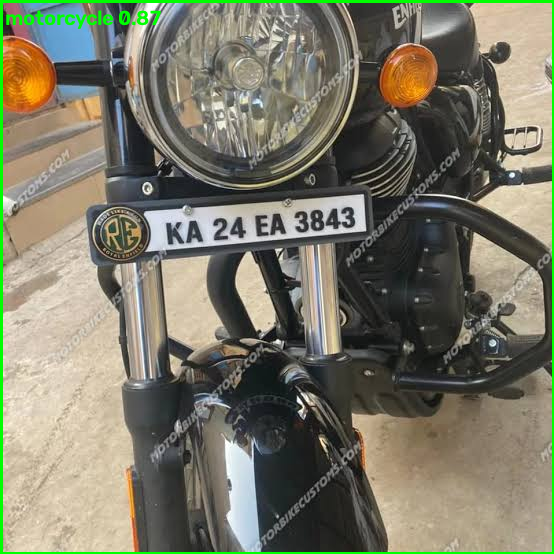

In [39]:
# Cell 11
# Display the final vehicle detection

from google.colab.patches import cv2_imshow

print("Final result")
print("Vehicles detected:", vehicle_count)

cv2_imshow(output)

In [40]:
# Cell 12
# Save the final detection result

OUTPUT_IMAGE = "vehicle_detection_result.jpg"

cv2.imwrite(
    OUTPUT_IMAGE,
    output
)

print("Image saved successfully:")
print(OUTPUT_IMAGE)

Image saved successfully:
vehicle_detection_result.jpg


In [41]:
# Cell 13
# Download the final image

files.download(OUTPUT_IMAGE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
# Cell 14
# Upload a video for vehicle detection

uploaded_video = files.upload()

VIDEO_PATH = list(uploaded_video.keys())[0]

print("Video selected:", VIDEO_PATH)

Saving Automatic Number Plate Recognition (ANPR) _ Vehicle Number Plate Recognition (1).mp4 to Automatic Number Plate Recognition (ANPR) _ Vehicle Number Plate Recognition (1).mp4
Video selected: Automatic Number Plate Recognition (ANPR) _ Vehicle Number Plate Recognition (1).mp4


In [43]:
# Cell 15
# Read basic information about the video

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise ValueError("Could not open the video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

duration = total_frames / fps if fps > 0 else 0

print("Video information")
print("----------------------")
print("Width:", width)
print("Height:", height)
print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration:", round(duration, 2), "seconds")

cap.release()

Video information
----------------------
Width: 1280
Height: 720
FPS: 30.0
Total frames: 930
Duration: 31.0 seconds


In [44]:
# Cell 16
# Function to send one video frame to Roboflow

import base64
import tempfile

def detect_vehicle(frame):

    # Save the frame temporarily
    temp_file = "temp_frame.jpg"

    cv2.imwrite(
        temp_file,
        frame
    )

    # Convert frame to Base64
    with open(temp_file, "rb") as image_file:
        image_bytes = image_file.read()

    frame_base64 = base64.b64encode(
        image_bytes
    ).decode("utf-8")

    # API request
    headers = {
        "Content-Type": "application/json"
    }

    payload = {
        "api_key": API_KEY,

        "inputs": {
            "image": {
                "type": "base64",
                "value": frame_base64
            },

            "classes": "car, truck, bus, bicycle, motorcycle"
        }
    }

    response = requests.post(
        API_URL,
        headers=headers,
        json=payload
    )

    # Check response
    if response.status_code != 200:
        print("API error:", response.status_code)
        return []

    result = response.json()

    # Extract predictions
    predictions = find_predictions(result)

    if predictions is None:
        return []

    return predictions


print("Video detection function created.")

Video detection function created.


In [45]:
# Cell 17
# Draw vehicle predictions on a video frame

def draw_vehicle_boxes(frame, predictions):

    output = frame.copy()

    counts = {
        "car": 0,
        "truck": 0,
        "bus": 0,
        "bicycle": 0,
        "motorcycle": 0
    }

    for prediction in predictions:

        confidence = float(
            prediction.get("confidence", 0)
        )

        if confidence < 0.30:
            continue

        class_name = prediction.get(
            "class",
            "vehicle"
        ).lower()

        x = float(prediction.get("x", 0))
        y = float(prediction.get("y", 0))
        width = float(prediction.get("width", 0))
        height = float(prediction.get("height", 0))

        # Center coordinates → corner coordinates
        x1 = int(x - width / 2)
        y1 = int(y - height / 2)
        x2 = int(x + width / 2)
        y2 = int(y + height / 2)

        # Keep coordinates inside frame
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(frame.shape[1], x2)
        y2 = min(frame.shape[0], y2)

        # Draw box
        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Label
        label = f"{class_name} {confidence:.2f}"

        cv2.putText(
            output,
            label,
            (x1, max(y1 - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 0),
            2
        )

        if class_name in counts:
            counts[class_name] += 1

    # Display statistics
    y_position = 30

    for vehicle, count in counts.items():

        cv2.putText(
            output,
            f"{vehicle.title()}: {count}",
            (15, y_position),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 255),
            2
        )

        y_position += 25

    total = sum(counts.values())

    cv2.putText(
        output,
        f"Total Vehicles: {total}",
        (15, y_position + 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 255),
        2
    )

    return output

In [46]:
# Cell 18
# Run vehicle detection on the video

INPUT_VIDEO = VIDEO_PATH
OUTPUT_VIDEO = "vehicle_detection_output.mp4"

cap = cv2.VideoCapture(INPUT_VIDEO)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Create output video
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    fps,
    (width, height)
)

# Run API every 5 frames
FRAME_SKIP = 5

frame_number = 0

last_predictions = []

while True:

    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1

    # Send every 5th frame to Roboflow
    if frame_number % FRAME_SKIP == 0:

        last_predictions = detect_vehicle(
            frame
        )

        print(
            f"Processed frame {frame_number}/{total_frames}"
        )

    # Draw the latest predictions
    output_frame = draw_vehicle_boxes(
        frame,
        last_predictions
    )

    # Write frame to output video
    out.write(output_frame)


cap.release()
out.release()

print()
print("Video processing completed!")
print("Output:", OUTPUT_VIDEO)

Processed frame 5/930
Processed frame 10/930
Processed frame 15/930
Processed frame 20/930
Processed frame 25/930
Processed frame 30/930
Processed frame 35/930
Processed frame 40/930
Processed frame 45/930
Processed frame 50/930
Processed frame 55/930
Processed frame 60/930
Processed frame 65/930
Processed frame 70/930
Processed frame 75/930
Processed frame 80/930
Processed frame 85/930
Processed frame 90/930
Processed frame 95/930
Processed frame 100/930
Processed frame 105/930
Processed frame 110/930
Processed frame 115/930
Processed frame 120/930
Processed frame 125/930
Processed frame 130/930
Processed frame 135/930
Processed frame 140/930
Processed frame 145/930
Processed frame 150/930
Processed frame 155/930
Processed frame 160/930
Processed frame 165/930
Processed frame 170/930
Processed frame 175/930
Processed frame 180/930
Processed frame 185/930
Processed frame 190/930
Processed frame 195/930
Processed frame 200/930
Processed frame 205/930
Processed frame 210/930
Processed fr

In [47]:
# Cell 19
# Display the processed video

from IPython.display import Video, display

display(
    Video(
        OUTPUT_VIDEO,
        embed=True
    )
)

In [48]:
# Cell 20
# Download the final detected video

files.download(
    OUTPUT_VIDEO
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>